# What changing the difference order really does

The order d in D_d describes which discrete derivative is penalized. For 1 ≤ d < n the null space is d-dimensional, consisting of sampled polynomials of degree at most d−1.

In [1]:
import awesomefigures as af
from matplotlib_inline.backend_inline import set_matplotlib_formats

# Publication styling only; numerical estimates and metrics are unchanged.
af.set_style("elegante", font="DejaVu Sans", use_tex=False,
             palette="okabe-ito", rasterize=False)
set_matplotlib_formats("svg", "png")

from trendestimation._docs_style import apply_documentation_figure_style
apply_documentation_figure_style()


## One signal, multiple orders

Keep the data and $\lambda$ fixed while varying the regularity penalty. Direct numerical comparisons at equal $\lambda$ are not equally smooth; compare normalized smoothness as well.

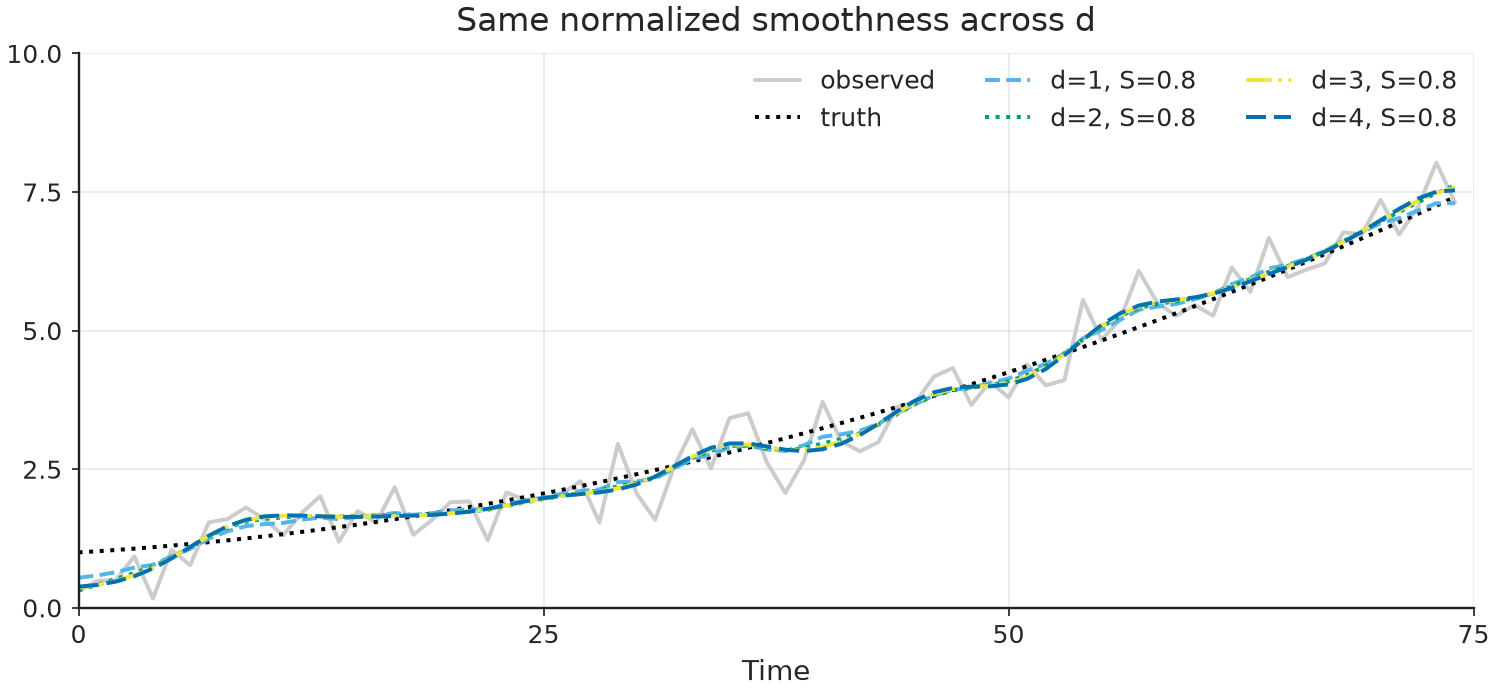

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from trendestimation import TrendSmoother,difference_matrix
rng=np.random.default_rng(8);t=np.arange(75)
truth=1+.02*t+.0009*t*t
y=truth+rng.normal(scale=.4,size=len(t))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(y,color="0.8",label="observed");ax.plot(truth,"k:",label="truth")
for d in [1,2,3,4]:
    sm=TrendSmoother(len(y),order=d)
    lam=sm.lambda_for_smoothness(.8)
    ax.plot(sm.fit(y,lambda_=lam).trend,label=f"d={d}, S=0.8")
ax.legend(ncol=3);ax.set(title="Same normalized smoothness across d",xlabel="Time");plt.show()

## Difference geometry

The matrix D_d has n−d rows, and every row contains binomial coefficients. Verify that polynomial degrees below d disappear under D_d.

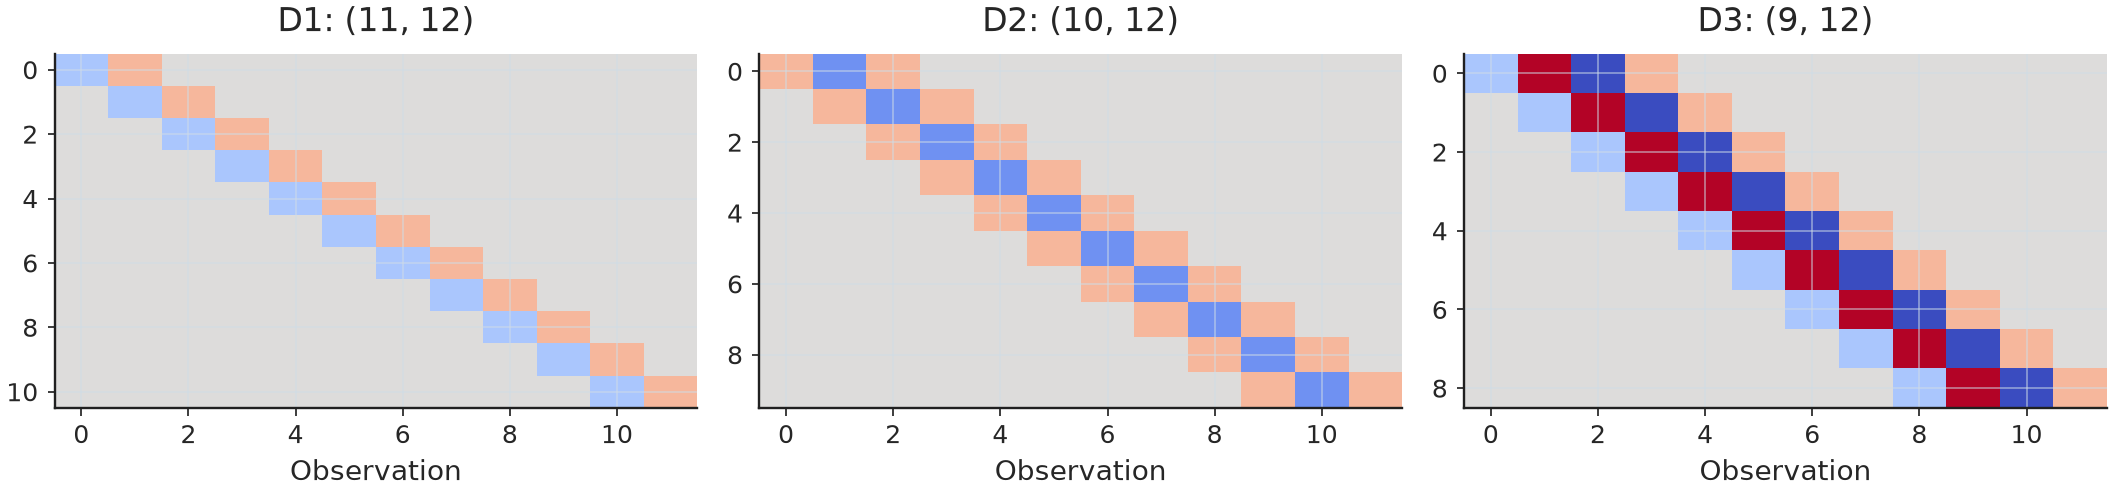

Rank identities verified for d=1,2,3,4.


In [3]:
fig,axes=plt.subplots(1,3,figsize=(12,3))
for a,d in zip(axes,[1,2,3]):
    D=difference_matrix(12,d)
    a.imshow(D,cmap="coolwarm",aspect="auto",vmin=-3,vmax=3)
    a.set(title=f"D{d}: {D.shape}",xlabel="Observation")
fig.tight_layout();plt.show()
for d in [1,2,3,4]:
    D=difference_matrix(40,d)
    assert np.linalg.matrix_rank(D)==40-d
print("Rank identities verified for d=1,2,3,4.")

## Exact infinite-penalty limits

At $\lambda=\infty$ the penalized differences vanish for $\mu=0$, leaving the best least-squares polynomial of degree $\le d-1$. No finite approximation to infinity is necessary.

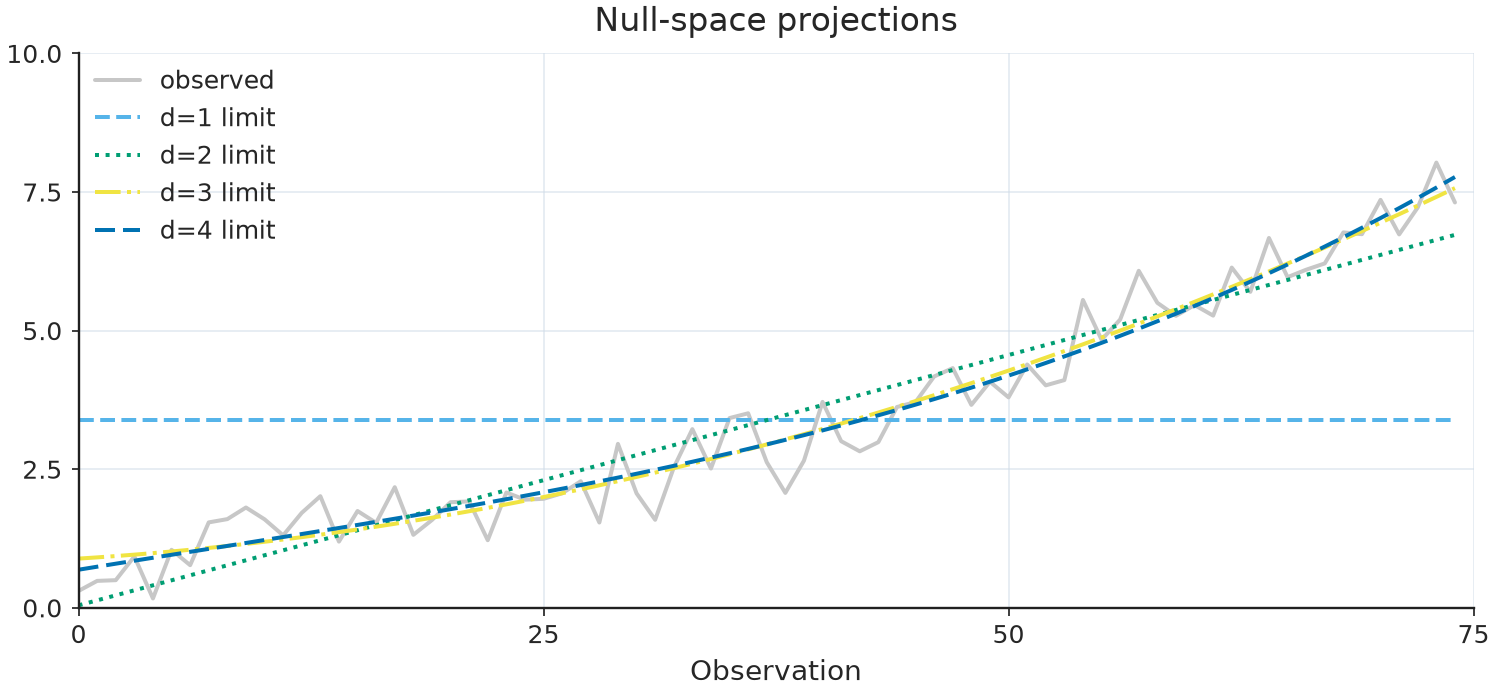

In [4]:
fig,ax=plt.subplots(figsize=(10,4));ax.plot(y,color="0.78",label="observed")
for d in [1,2,3,4]:
    sm=TrendSmoother(len(y),d)
    fit=sm.fit(y,lambda_=float("inf"))
    assert np.linalg.norm(sm.D@fit.trend)<1e-7
    ax.plot(fit.trend,label=f"d={d} limit")
ax.set(title="Null-space projections",xlabel="Observation");ax.legend();plt.show()

## Matched penalty and smoothness score plots

For the current notebook data (or a labeled synthetic fallback), compare CV, GCV, AICc and BIC versus $\lambda$ **and** $S(\lambda)$; the mapped grids have identical candidate penalties. Each execution saves inline SVG and PNG figures. The single GCV selector timing is illustrative and is **not** a controlled speed comparison; use the separate multi-seed benchmark for that.

Paired coordinates: last 60 observations of the notebook series; n=60, d=2, mu=0
Normalized S grid: [0.       0.1      0.2      0.3      0.4      0.5      0.6      0.7
 0.8      0.9      0.95     0.99     0.999    0.9999   0.999999 1.      ]
S=0 maps to lambda=0; S=1 maps to lambda=+infinity.
Near-1 targets: S=0.950000 -> lambda=886.169, S=0.990000 -> lambda=33003.8, S=0.999000 -> lambda=510198, S=0.999900 -> lambda=5.29957e+06, S=0.999999 -> lambda=5.32145e+08
Maximum inversion / round-trip error: 1.33e-15


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


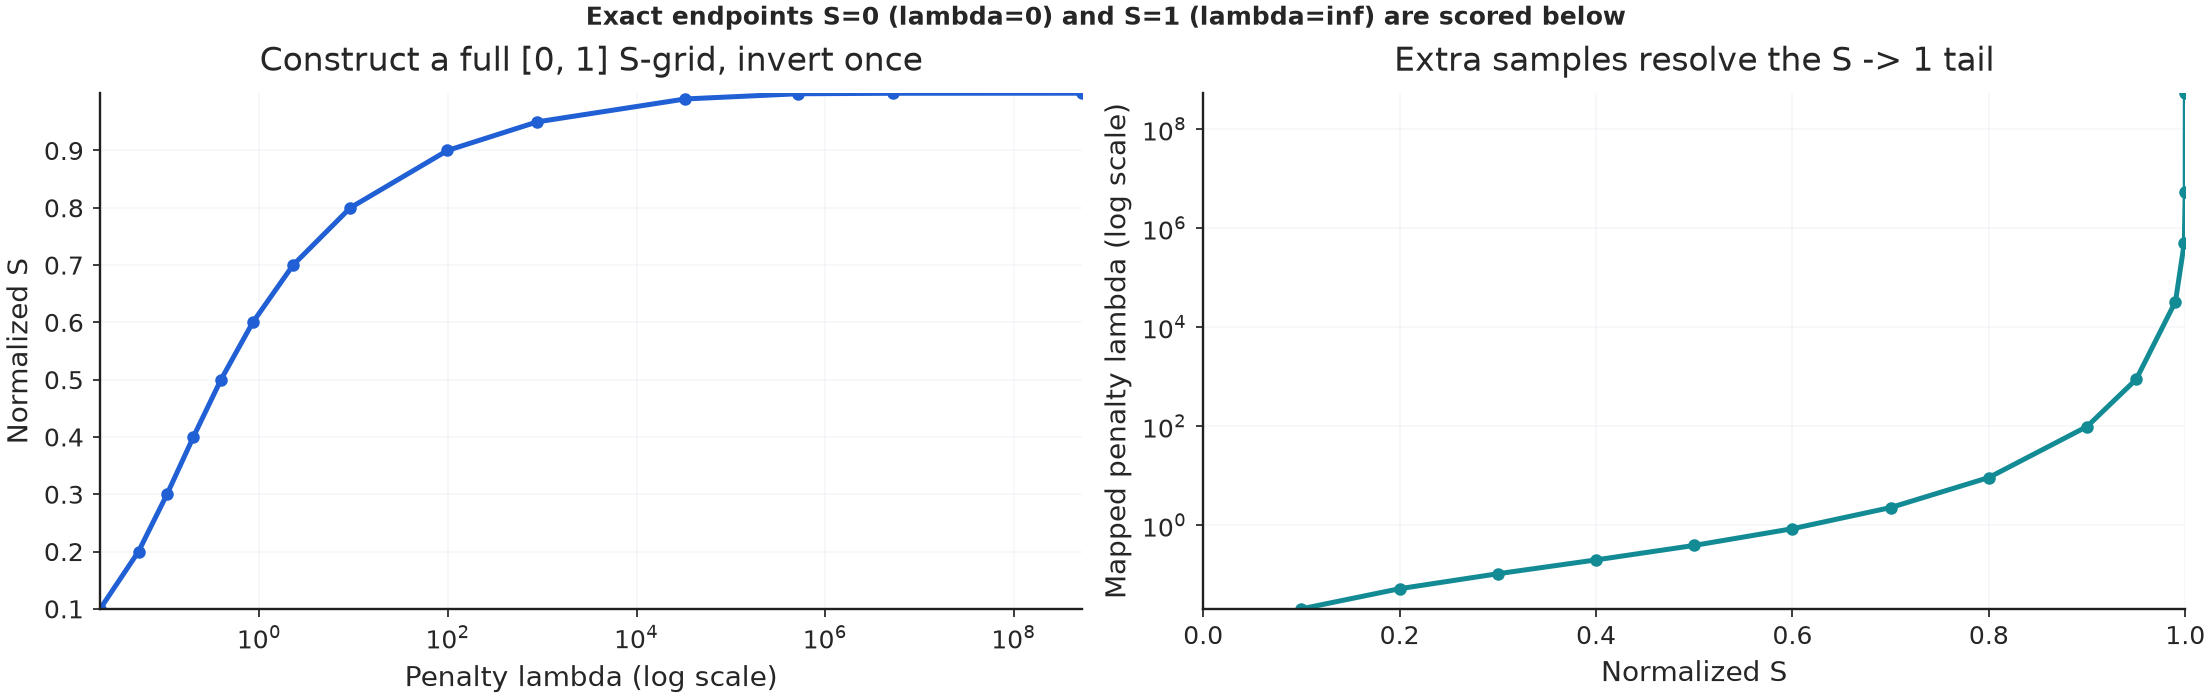

  CV: lambda=    886.169, S=0.95, score=0.202915
 GCV: lambda=    886.169, S=0.95, score=0.204574
AICC: lambda=    886.169, S=0.95, score=-1.55383
 BIC: lambda=  0.0205109, S=0.1, score=-2.10897


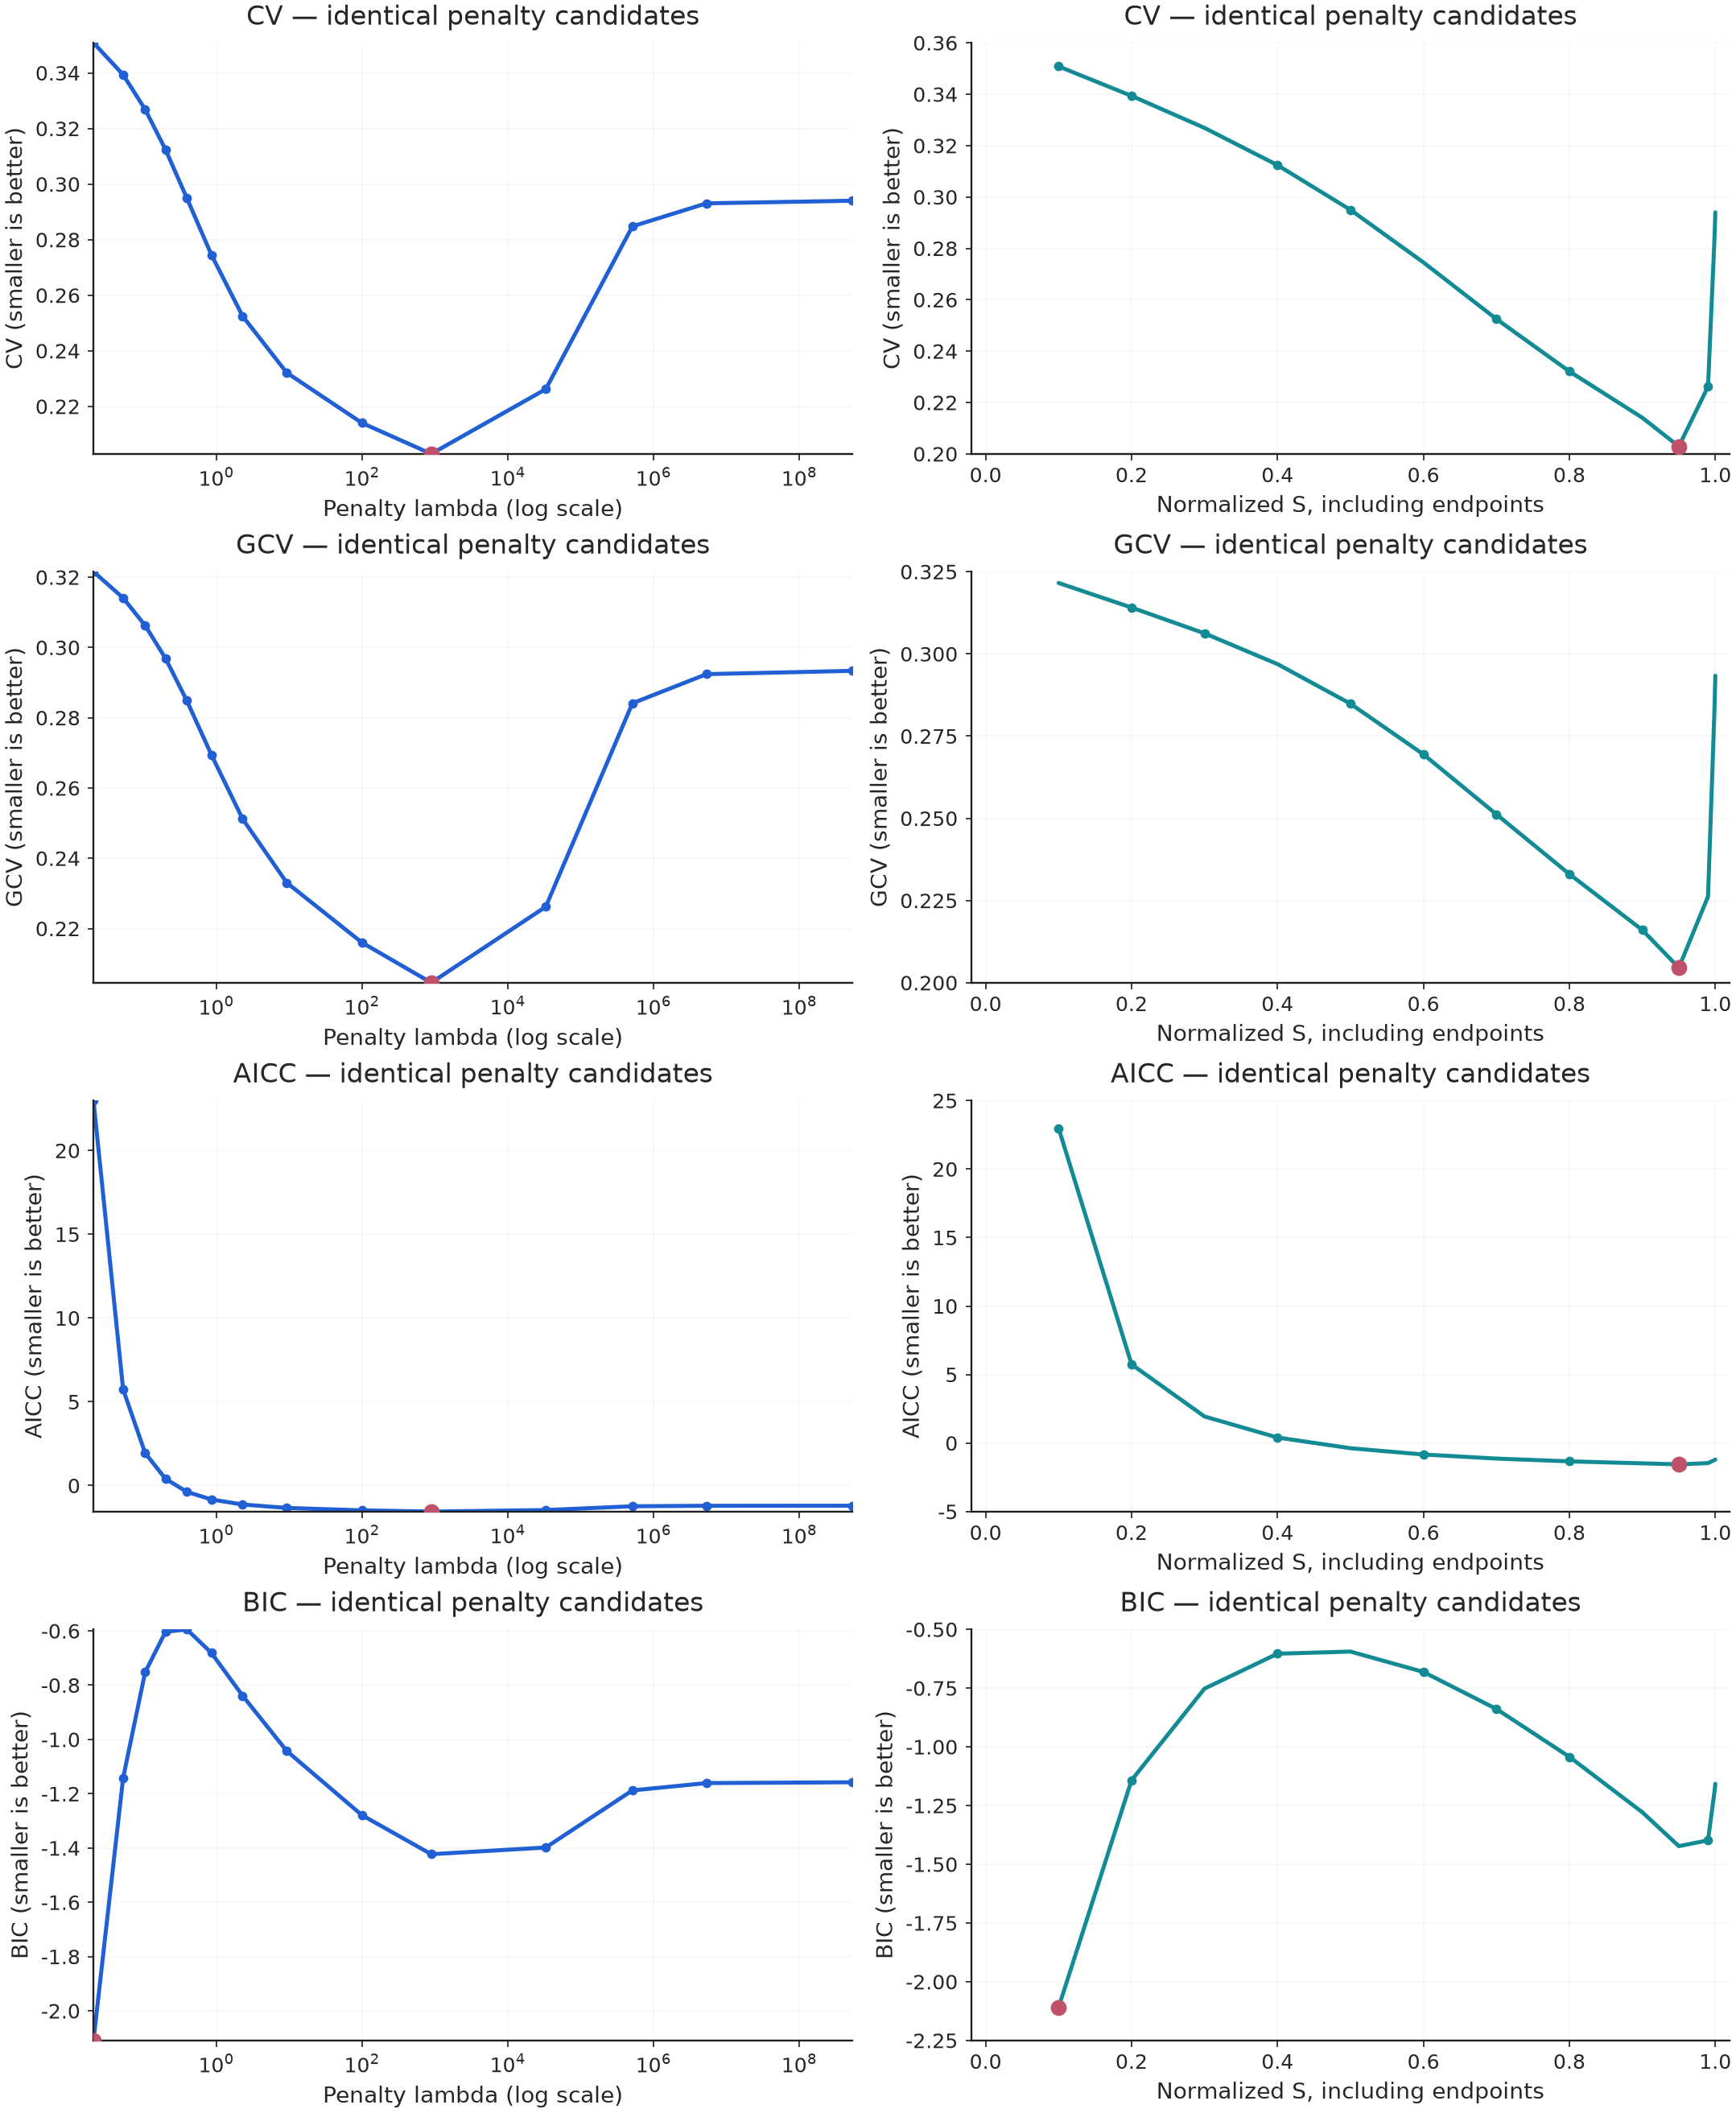

Left log-lambda plots omit 0 and infinity as coordinates, NOT as evaluated candidates. Right S plots include those endpoints. CV can be infinite at S=0 because unregularized LOOCV is undefined.


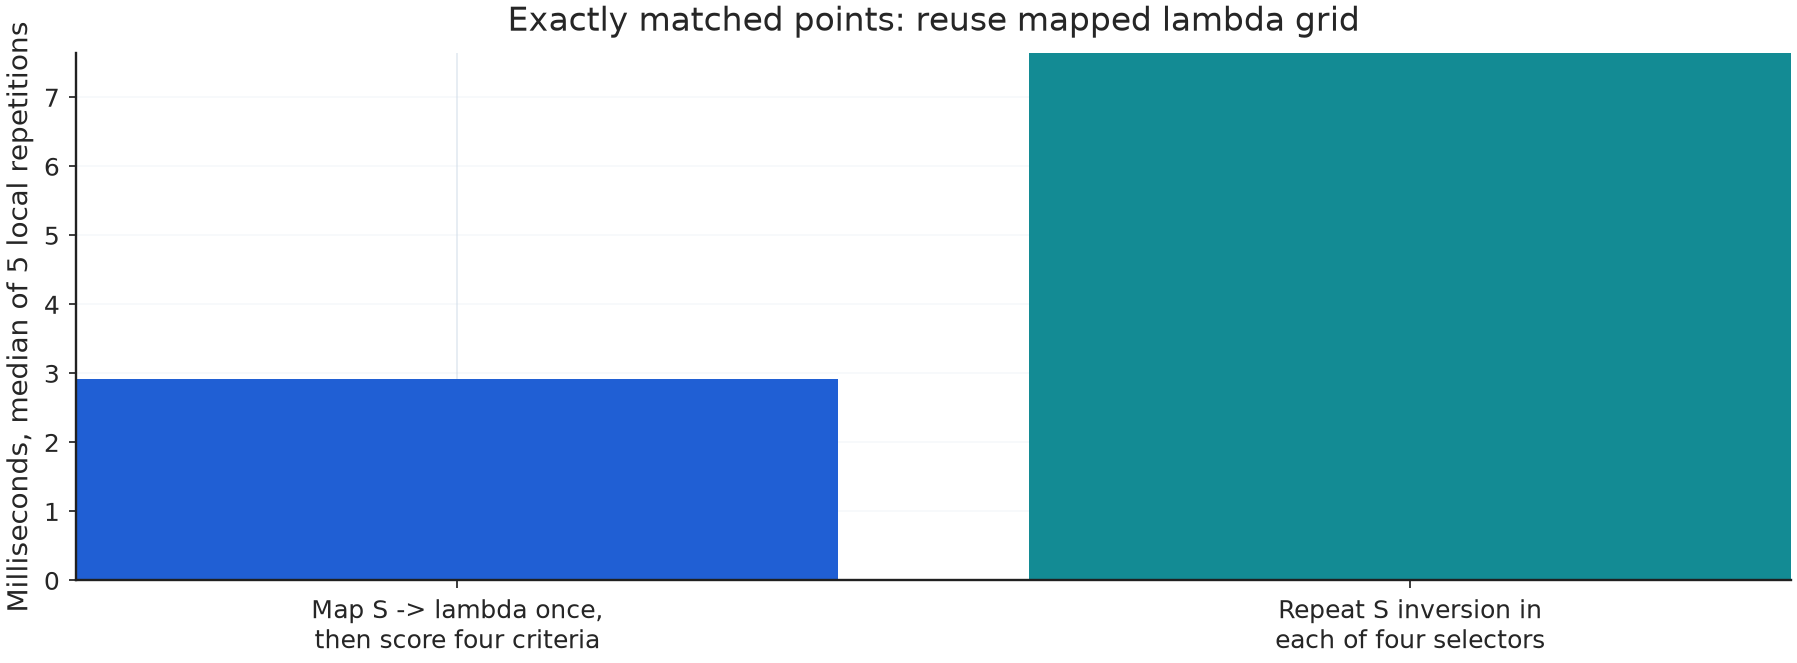

Four-criterion sweep, lambda-map-once: 2.915 ms; direct S selector (repeated mapping): 7.638 ms.
Both evaluate the same 16 penalties. This small, single-session measurement isolates a reusable-grid workflow, not the general speed of every optimization method or back end.


In [5]:
from trendestimation._docs_coordinates import show_dual_coordinate_gallery

_coordinate_series = next((globals()[name] for name in
                           ("history", "y", "observed", "series")
                           if name in globals()), None)
show_dual_coordinate_gallery(_coordinate_series, order=2, mu=0.0)
